# Eksploracja danych · Laboratorium 4
## Wykrywanie anomalii w dostawach (spotkanie 1): diagnostyka, IQR, model normy, k-means, Isolation Forest

**Dane:** `dane/dostawy_styczen.csv`: 1500 dostaw ze stycznia 2026 r. (dane syntetyczne).

| Kolumna | Opis |
|---|---|
| `id_dostawy` | identyfikator (**nie** jest cechą) |
| `data` | dzień dostawy (poniedziałek–sobota) |
| `odleglosc_km`, `masa_kg` | odległość trasy i masa przesyłki |
| `ekspres` | 1 = usługa ekspresowa |
| `czas_h`, `opoznienie_h` | czas przejazdu i opóźnienie względem planu [h] |
| `koszt_pln` | koszt dostawy [zł] |
| `etykieta`, `typ_anomalii` | prawda syntetyczna: 45 rekordów zmodyfikowanych celowo. **Tylko do oceny, nigdy jako cecha.** |

**Zasada pracy:** każdą decyzję zapisujemy w komórce tekstowej: co, ile wierszy, dlaczego. Wyniki kontrolne są w karcie zadań.
Przed oddaniem: *Kernel → Restart Kernel and Run All Cells*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
pd.set_option("display.precision", 2)

## Z1. Wczytanie i diagnostyka przed modelowaniem

In [2]:
df = pd.read_csv("dane/dostawy_styczen.csv", parse_dates=["data"])
df["typ_anomalii"] = df["typ_anomalii"].fillna("")
CECHY = ["odleglosc_km", "masa_kg", "ekspres", "czas_h", "opoznienie_h", "koszt_pln"]
y = df["etykieta"].to_numpy()          # tylko do oceny

print("wiersze:", len(df))
print("braki:", df[CECHY].isna().sum().sum())
print("duplikaty id:", df.id_dostawy.duplicated().sum())
print("ujemne wartości:", (df[CECHY] < 0).sum().sum())
print("udział ekspres:", df.ekspres.mean())
print(df.loc[y == 1, "typ_anomalii"].value_counts())
df[CECHY].describe()

wiersze: 1500
braki: 0
duplikaty id: 0
ujemne wartości: 0
udział ekspres: 0.176
typ_anomalii
opóźnienie +35 h    15
koszt ×3,5          15
koszt +1600 zł      15
Name: count, dtype: int64
Out[2]: 
       odleglosc_km  masa_kg  ekspres   czas_h  opoznienie_h  koszt_pln
count       1500.00  1500.00  1500.00  1500.00       1500.00    1500.00
mean         292.41   195.44     0.18     6.36          1.99    1221.90
std          180.29   161.47     0.38     3.06          4.02     735.66
min           30.90    10.60     0.00     1.45          0.00     270.99
25%          167.28    90.25     0.00     4.20          0.40     783.07
50%          247.75   148.45     0.00     5.63          0.90    1057.89
75%          370.05   240.93     0.00     7.74          1.85    1448.58
max         1200.00  1500.00     1.00    22.30         39.04   11682.82


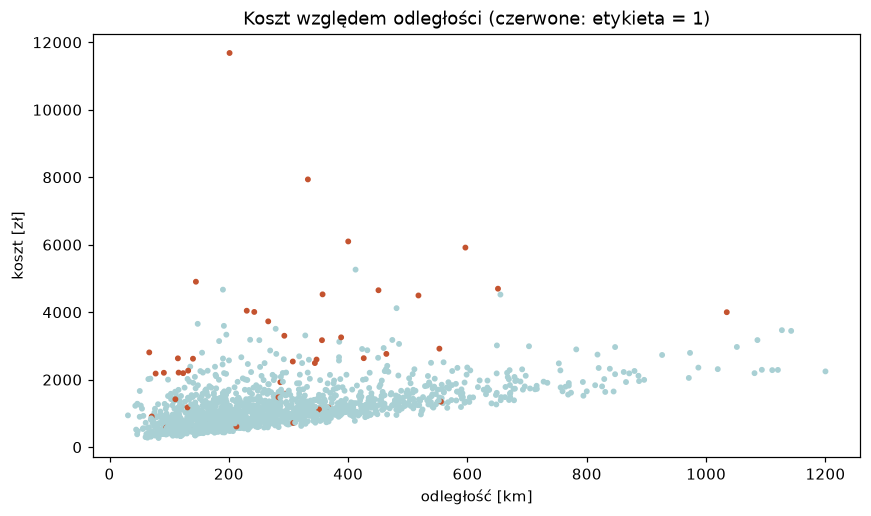

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df.odleglosc_km, df.koszt_pln, s=8, c=np.where(y == 1, "#C4532F", "#A9D0D4"))
ax.set_xlabel("odległość [km]"); ax.set_ylabel("koszt [zł]"); ax.set_title("Koszt względem odległości (czerwone: etykieta = 1)")
plt.show()

**Pytanie:** dlaczego wykres kosztu względem odległości jest ważniejszy niż histogram samego kosztu?

*Odpowiedź:* Koszt zależy od długości trasy: wysoka kwota na długiej trasie może być prawidłowa, a na krótkiej oznaczać zawyżenie. Wykres pokazuje ten kontekst, którego nie widać na histogramie.

## Z2. Reguła IQR na koszcie (punkt odniesienia)

In [4]:
def metryki(y, alarm, c_alarm=25, c_fn=800):
    y = np.asarray(y).astype(bool); a = np.asarray(alarm).astype(bool)
    tp = (y & a).sum(); fp = (~y & a).sum(); fn = (y & ~a).sum()
    p = tp / a.sum() if a.sum() else 0; r = tp / y.sum() if y.sum() else 0
    f1 = 2 * p * r / (p + r) if p + r else 0
    return {"alarmy": int(a.sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
            "precision": round(float(p), 4), "recall": round(float(r), 4), "F1": round(float(f1), 4), "koszt": int(c_alarm * a.sum() + c_fn * fn)}

def recall_wg_typu(df, alarm):
    t = df["typ_anomalii"]; a = pd.Series(np.asarray(alarm), index=df.index)
    return a[t != ""].groupby(t[t != ""]).mean().round(4)

q1, q3 = df.koszt_pln.quantile([0.25, 0.75])
iqr = q3 - q1; gorny = q3 + 1.5 * iqr
a_iqr = (df.koszt_pln > gorny).to_numpy()
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}, górny próg = {gorny:.2f}")
print(metryki(y, a_iqr))
print(recall_wg_typu(df, a_iqr))

Q1 = 783.07, Q3 = 1448.58, IQR = 665.51, górny próg = 2446.84
{'alarmy': 73, 'TP': 25, 'FP': 48, 'FN': 20, 'precision': 0.3425, 'recall': 0.5556, 'F1': 0.4237, 'koszt': 17825}
typ_anomalii
koszt +1600 zł      0.67
koszt ×3,5          1.00
opóźnienie +35 h    0.00
dtype: float64


**Pytania:** (1) Ile alarmów IQR to dostawy bez etykiety i jaką mają średnią odległość? (2) Dlaczego IQR na koszcie nie wykrywa ani jednej anomalii typu „opóźnienie +35 h”? (3) Które dostawy „koszt +1600 zł” przeoczył?

*Odpowiedź:* IQR daje 48 fałszywych alarmów, o średniej odległości 471,91 km. Anomalie opóźnienia nie muszą zwiększać kosztu, więc próg kosztowy ich nie wykrywa. Przeoczone dopłaty +1600 zł dotyczą dostaw o niskim koszcie bazowym: mimo dopłaty pozostają poniżej 2446,84 zł. Poniżej lista konkretnych dostaw.

In [5]:
print("FP: średnia odległość", df.loc[a_iqr & (y == 0), "odleglosc_km"].mean())
display(df.loc[(df.typ_anomalii.str.contains("1600")) & ~a_iqr, ["id_dostawy", "odleglosc_km", "koszt_pln", "typ_anomalii"]])

FP: średnia odległość 471.9083333333333


,id_dostawy,odleglosc_km,koszt_pln,typ_anomalii
457,2601-0458,77.3,2181.21,koszt +1600 zł
794,2601-0795,131.8,2267.45,koszt +1600 zł
867,2601-0868,123.4,2192.77,koszt +1600 zł
923,2601-0924,115.8,2209.34,koszt +1600 zł
1186,2601-1187,91.1,2204.34,koszt +1600 zł


## Z3. Z-score klasyczny i odporny

In [6]:
z = (df.koszt_pln - df.koszt_pln.mean()) / df.koszt_pln.std()
print("|z| > 3:", metryki(y, (z.abs() > 3).to_numpy()))
med = df.koszt_pln.median(); mad = (df.koszt_pln - med).abs().median()
z_odp = (df.koszt_pln - med) / (1.4826 * mad)
print("z odporny > 3,5:", metryki(y, (z_odp > 3.5).to_numpy()))
print("średnia z anomaliami / bez:", round(df.koszt_pln.mean(), 2), round(df.koszt_pln[y == 0].mean(), 2))
print("odchylenie z anomaliami / bez:", round(df.koszt_pln.std(), 2), round(df.koszt_pln[y == 0].std(), 2))
print("mediana z anomaliami / bez:", round(med, 2), round(df.koszt_pln[y == 0].median(), 2))

|z| > 3: {'alarmy': 22, 'TP': 13, 'FP': 9, 'FN': 32, 'precision': 0.5909, 'recall': 0.2889, 'F1': 0.3881, 'koszt': 26150}
z odporny > 3,5: {'alarmy': 50, 'TP': 19, 'FP': 31, 'FN': 26, 'precision': 0.38, 'recall': 0.4222, 'F1': 0.4, 'koszt': 22050}
średnia z anomaliami / bez: 1221.9 1169.33
odchylenie z anomaliami / bez: 735.66 574.08
mediana z anomaliami / bez: 1057.89 1050.82


**Pytanie:** co się stało z odchyleniem standardowym po dodaniu 45 anomalii i dlaczego to „maskuje” część z nich?

*Odpowiedź:* Odchylenie wzrosło z 574,08 do 735,66 zł. Większy mianownik zmniejsza z-score, a wzrost średniej dodatkowo przybliża do niej wysokie koszty. Dlatego klasyczny z-score maskuje część anomalii. Mediana i MAD reagują słabiej.

## Z4. Model normy: koszt oczekiwany dla trasy i opóźnienie względem dnia

Anomalia to odstępstwo od **oczekiwania**, a nie od średniej. Krok po kroku:
1. regresja kosztu na odległości, masie, ekspresie (i sobocie),
2. reszta = koszt − koszt oczekiwany,
3. odporny z reszty i opóźnienia; alarm, gdy większy z nich > 3,5.

In [7]:
def odporny_z(x):
    med = x.median(); skala = 1.4826 * (x - med).abs().median()
    return (x - med) / skala

def regula(df, cechy_kosztu, kol_opoznienia, prog=3.5):
    m = LinearRegression().fit(df[cechy_kosztu], df.koszt_pln)
    reszta = df.koszt_pln - m.predict(df[cechy_kosztu])
    wynik = np.maximum(odporny_z(reszta), odporny_z(df[kol_opoznienia]))
    return wynik, m

df["sobota"] = (df.data.dt.weekday == 5).astype(int)
w1, m1 = regula(df, ["odleglosc_km", "masa_kg", "ekspres"], "opoznienie_h")
print("v1:", metryki(y, (w1 > 3.5).to_numpy()))

v1: {'alarmy': 217, 'TP': 45, 'FP': 172, 'FN': 0, 'precision': 0.2074, 'recall': 1.0, 'F1': 0.3435, 'koszt': 5425}


Skąd tyle fałszywych alarmów? Popatrz na opóźnienia **dzień po dniu** (anomalia zbiorowa).

data
2026-01-24    1.08
2026-01-14    7.18
2026-01-27    7.29
Name: opoznienie_h, dtype: float64
FP v1 w dniach ['14.01', '27.01'] : 129 z 172


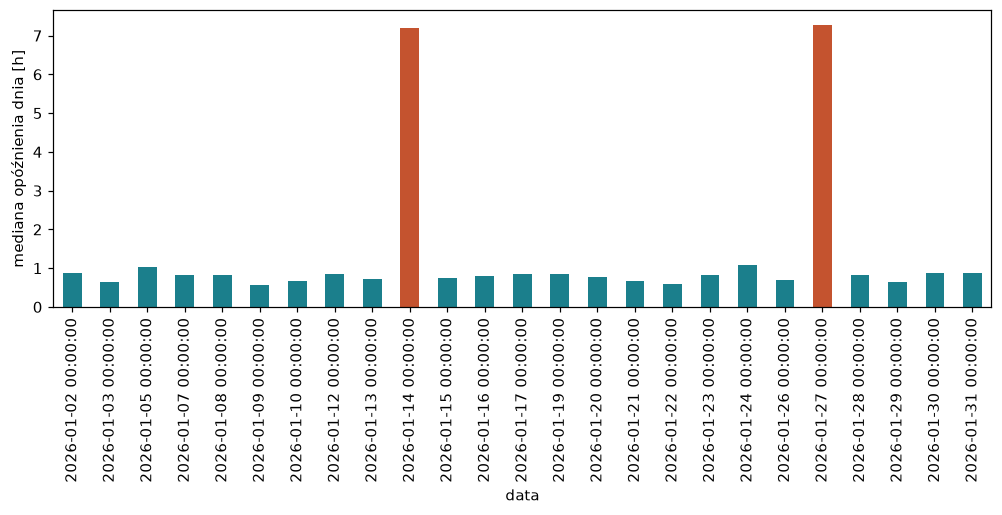

In [8]:
dzien = df.groupby("data").opoznienie_h.median()
dzien.plot(kind="bar", figsize=(11, 3.5), color=np.where(dzien > 3, "#C4532F", "#1B7F8C"))
plt.ylabel("mediana opóźnienia dnia [h]"); plt.show()
print(dzien.sort_values().tail(3))
fp1 = df[(w1 > 3.5).to_numpy() & (y == 0)]
print("FP v1 w dniach", list(dzien[dzien > 3].index.strftime("%d.%m")), ":", fp1.data.isin(dzien[dzien > 3].index).sum(), "z", len(fp1))

In [9]:
df["opoznienie_wzgl_dnia"] = df.opoznienie_h - df.groupby("data").opoznienie_h.transform("median")
w3, m3 = regula(df, ["odleglosc_km", "masa_kg", "ekspres", "sobota"], "opoznienie_wzgl_dnia")
a3 = (w3 > 3.5).to_numpy()
print("v3:", metryki(y, a3))
print(recall_wg_typu(df, a3))
print("Współczynniki v3:", dict(zip(m3.feature_names_in_, m3.coef_)))
# Oddzielny pomiar efektu normalizacji dnia, przy tych samych cechach kosztu:
w_dzien, _ = regula(df, ["odleglosc_km", "masa_kg", "ekspres"], "opoznienie_wzgl_dnia")
print("FP po samej normalizacji dnia:", metryki(y, w_dzien > 3.5)["FP"])


v3: {'alarmy': 109, 'TP': 45, 'FP': 64, 'FN': 0, 'precision': 0.4128, 'recall': 1.0, 'F1': 0.5844, 'koszt': 2725}
typ_anomalii
koszt +1600 zł      1.0
koszt ×3,5          1.0
opóźnienie +35 h    1.0
dtype: float64
Współczynniki v3: {'odleglosc_km': np.float64(1.8940093416771768), 'masa_kg': np.float64(3.033455692246564), 'ekspres': np.float64(185.16678488621045), 'sobota': np.float64(165.2006236428886)}
FP po samej normalizacji dnia: 70


**Pytania:** (1) Ile fałszywych alarmów usunęła kolumna opóźnienia względem dnia? (2) Co wykrywa współczynnik przy `sobota` (porównaj z kosztem bez soboty)? (3) Czy dostawa ze śnieżnego dnia, opóźniona o 7 h, jest anomalią?

*Odpowiedź:* Łączne przejście z v1 do v3 zmniejsza liczbę FP ze 172 do 64, czyli o 108. Zmieniają się jednocześnie dwie rzeczy: normalizacja opóźnienia oraz cecha soboty; oddzielny wynik po samej normalizacji jest wyliczony powyżej. Współczynnik soboty ok. 165,20 zł opisuje dopłatę weekendową przy pozostałych cechach stałych. Opóźnienie 7 h w dniu, w którym podobnie opóźniona jest większość dostaw, nie musi być anomalią pojedynczej dostawy; warto osobno zgłosić problem całego dnia.

## Z5. K-means i Isolation Forest na standaryzowanych cechach

In [10]:
X = StandardScaler().fit_transform(df[CECHY])
for k in range(2, 9):
    print(k, round(silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)), 4))

2 0.3693
3 0.4022
4 0.4119
5 0.4339
6 0.3504
7 0.361
8 0.361


In [11]:
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X)
w_km = km.transform(X).min(axis=1)                                          # odległość do najbliższego centroidu
iforest = IsolationForest(n_estimators=300, random_state=0).fit(X)
w_if = -iforest.score_samples(X)                                          # wyżej = bardziej nietypowy

def top(wynik, n):
    a = np.zeros(len(wynik), dtype=bool); a[np.argsort(-np.asarray(wynik), kind="stable")[:n]] = True
    return a

BUDZET = 60
for nazwa, w in [("IQR koszt", df.koszt_pln.to_numpy()), ("Model normy", w3.to_numpy()), ("K-means", w_km), ("Isolation Forest", w_if)]:
    print(f"{nazwa:18s}", metryki(y, top(w, BUDZET)))

IQR koszt          {'alarmy': 60, 'TP': 22, 'FP': 38, 'FN': 23, 'precision': 0.3667, 'recall': 0.4889, 'F1': 0.419, 'koszt': 19900}
Model normy        {'alarmy': 60, 'TP': 45, 'FP': 15, 'FN': 0, 'precision': 0.75, 'recall': 1.0, 'F1': 0.8571, 'koszt': 1500}
K-means            {'alarmy': 60, 'TP': 17, 'FP': 43, 'FN': 28, 'precision': 0.2833, 'recall': 0.3778, 'F1': 0.3238, 'koszt': 23900}
Isolation Forest   {'alarmy': 60, 'TP': 20, 'FP': 40, 'FN': 25, 'precision': 0.3333, 'recall': 0.4444, 'F1': 0.381, 'koszt': 21500}


In [12]:
for c in (0.01, 0.03, 0.05, 0.10):
    m = IsolationForest(n_estimators=300, contamination=c, random_state=0).fit(X)
    print("contamination", c, "→ alarmów:", (m.predict(X) == -1).sum())
print("Recall IF według typu:", recall_wg_typu(df, top(w_if, BUDZET)))


contamination 0.01 → alarmów: 15
contamination 0.03 → alarmów: 45
contamination 0.05 → alarmów: 75
contamination 0.1 → alarmów: 150
Recall IF według typu: typ_anomalii
koszt +1600 zł      0.13
koszt ×3,5          0.33
opóźnienie +35 h    0.87
dtype: float64


**Pytania:** (1) Dlaczego budżet alarmów (60 dostaw miesięcznie) jest uczciwszym porównaniem niż `contamination=0.03`? (2) Które typy anomalii widzi Isolation Forest, a których nie? (`recall_wg_typu`)

*Odpowiedź:* Stały budżet porównuje metody przy takim samym nakładzie pracy: 60 kontroli. Contamination narzuca udział alarmów w Isolation Forest, lecz nie zapewnia takiego samego budżetu dla pozostałych metod. Recall IF według typu obliczamy poniżej; wysoki koszt jest globalnie nietypowy, natomiast umiarkowana dopłata lub opóźnienie w lokalnym kontekście mogą pozostać niezauważone.

## Z6. Tabela wyników i ranking

In [13]:
wyniki = df[["id_dostawy", "data"] + CECHY].copy()
wyniki["model_normy"] = w3.to_numpy(); wyniki["kmeans"] = w_km; wyniki["isolation_forest"] = w_if
rangi = wyniki[["model_normy", "kmeans", "isolation_forest"]].rank(ascending=False)
wyniki["ranga_srednia"] = rangi.mean(axis=1)
wyniki.sort_values("ranga_srednia").to_csv("wyniki_styczen.csv", index=False)
wyniki.sort_values("ranga_srednia").head(10)

Out[13]: 
     id_dostawy       data  ...  isolation_forest  ranga_srednia
1085  2601-1086 2026-01-24  ...              0.70           1.67
78    2601-0079 2026-01-03  ...              0.61          17.67
335   2601-0336 2026-01-09  ...              0.62          17.67
606   2601-0607 2026-01-15  ...              0.69          20.33
1449  2601-1450 2026-01-31  ...              0.59          23.00
1075  2601-1076 2026-01-24  ...              0.63          26.00
1358  2601-1359 2026-01-30  ...              0.62          27.00
1241  2601-1242 2026-01-28  ...              0.64          34.67
1452  2601-1453 2026-01-31  ...              0.63          36.67
125   2601-0126 2026-01-05  ...              0.57          39.33

[10 rows x 12 columns]


## Z7. Hipotezy biznesowe

Zapisz trzy hipotezy, co mogło się stać z dostawami z czołówki rankingu (np. błąd stawki, zła jednostka, awaria pojazdu), i jak je sprawdzić (kogo zapytać, jaki dokument).

*Odpowiedź:* Hipotezy wymagają sprawdzenia dokumentów; wysoki wynik nie dowodzi błędu. Dla pierwszych trzech dostaw rankingu poniżej zapisujemy hipotezy i sposób weryfikacji.

In [14]:
hipotezy = wyniki.sort_values("ranga_srednia").head(3)[["id_dostawy", "koszt_pln", "opoznienie_h"]].copy()
hipotezy["hipoteza"] = ["Błędny mnożnik stawki lub jednostka kosztu", "Podwójnie naliczona dopłata lub dodatkowa usługa", "Zaniżona odległość w zleceniu lub rozliczenie innej trasy"]
hipotezy["jak_sprawdzic"] = ["Dział rozliczeń: faktura, cennik i zlecenie przewozu", "Przewoźnik: pozycje faktury i potwierdzenie zamówionej usługi", "Dyspozytor i rozliczenia: GPS, CMR, adresy trasy i numer zlecenia na fakturze"]
display(hipotezy)

,id_dostawy,koszt_pln,opoznienie_h,hipoteza,jak_sprawdzic
1085,2601-1086,11682.82,1.11,Błędny mnożnik stawki lub jednostka kosztu,"Dział rozliczeń: faktura, cennik i zlecenie pr..."
78,2601-0079,7935.88,0.42,Podwójnie naliczona dopłata lub dodatkowa usługa,Przewoźnik: pozycje faktury i potwierdzenie za...
335,2601-0336,5915.29,0.42,Zaniżona odległość w zleceniu lub rozliczenie ...,"Dyspozytor i rozliczenia: GPS, CMR, adresy tra..."
